# A/B Testing: Did a New Landing Page Improve Conversions?

**Portfolio project** | Python, Pandas, Matplotlib, Statsmodels

**Question:** Is the conversion rate different between the old landing page (control) and the new page (treatment)?

This is a historical educational dataset; the analysis does not imply a currently running experiment. We analyze conversion as a binary outcome and users as the unit of observation. The analysis is exploratory and does not substitute for a preregistered experiment design.

## 1. Load data
Data source: [Udacity A/B testing dataset on Kaggle](https://www.kaggle.com/datasets/zhangluyuan/ab-testing). This notebook retrieves a publicly hosted copy from GitHub; if it is unavailable, download `ab_data.csv` from Kaggle and upload it to Colab, then replace the URL with `ab_data.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

url = "https://raw.githubusercontent.com/beery4010/Analyze-AB-Test-Results/master/ab_data.csv"
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [2]:

print(df["group"].value_counts())
 

group
treatment    147276
control      147202
Name: count, dtype: int64


In [3]:

conversion_rates = df.groupby("group")["converted"].mean() * 100

print(conversion_rates)


group
control      12.039918
treatment    11.891958
Name: converted, dtype: float64


In [4]:

duplicates = df.duplicated(subset="user_id").sum()

print("Number of duplicate user IDs:", duplicates)


Number of duplicate user IDs: 3894


In [5]:

print(pd.crosstab(df["group"], df["landing_page"]))


landing_page  new_page  old_page
group                           
control           1928    145274
treatment       145311      1965


In [6]:

df_clean = df[
    ((df["group"] == "control") & (df["landing_page"] == "old_page")) |
    ((df["group"] == "treatment") & (df["landing_page"] == "new_page"))
].copy()

print("Original records:", len(df))
print("Matched records:", len(df_clean))


Original records: 294478
Matched records: 290585


In [7]:

duplicates = df_clean.duplicated(subset="user_id").sum()

print("Duplicate users remaining:", duplicates)


Duplicate users remaining: 1


In [8]:

duplicate_rows = df_clean[
    df_clean.duplicated(subset="user_id", keep=False)
]

print(duplicate_rows)


      user_id                   timestamp      group landing_page  converted
1899   773192  2017-01-09 05:37:58.781806  treatment     new_page          0
2893   773192  2017-01-14 02:55:59.590927  treatment     new_page          0


In [9]:

df_clean = df_clean.drop_duplicates(
    subset="user_id",
    keep="first"
).copy()

print("Final records:", len(df_clean))

print("Duplicates remaining:", df_clean.duplicated(subset="user_id").sum())


Final records: 290584
Duplicates remaining: 0


In [10]:

control_rate = conversion_rates["control"]
treatment_rate = conversion_rates["treatment"]

difference = treatment_rate - control_rate

print("Difference:", round(difference, 4), "percentage points")


Difference: -0.148 percentage points


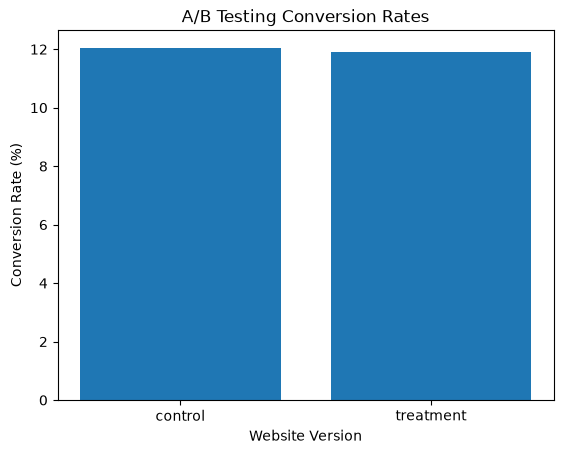

In [11]:

import matplotlib.pyplot as plt


plt.bar( conversion_rates.index, conversion_rates.values)

# Add labels
plt.title("A/B Testing Conversion Rates")
plt.xlabel("Website Version")
plt.ylabel("Conversion Rate (%)")


plt.show()


In [12]:

from statsmodels.stats.proportion import proportions_ztest

# Count conversions in each group
conversions = df_clean.groupby("group")["converted"].sum()

# Count users in each group
users = df_clean.groupby("group")["user_id"].count()

# Perform a two-sided Z-test
z_stat, p_value = proportions_ztest(
    count=[
        conversions["treatment"],
        conversions["control"]
    ],
    nobs=[
        users["treatment"],
        users["control"]
    ],
    alternative="two-sided"
)

print("Z-statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 6))


Z-statistic: -1.3109
P-value: 0.189883


In [13]:

conversions = df_clean.groupby("group")["converted"].sum()

users = df_clean.groupby("group")["user_id"].count()

print("Conversions:")
print(conversions)

print("Users:")
print(users)


Conversions:
group
control      17489
treatment    17264
Name: converted, dtype: int64
Users:
group
control      145274
treatment    145310
Name: user_id, dtype: int64


In [14]:

from statsmodels.stats.proportion import confint_proportions_2indep

lower, upper = confint_proportions_2indep(
    count1=conversions["treatment"],
    nobs1=users["treatment"],
    count2=conversions["control"],
    nobs2=users["control"],
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("95% Confidence Interval:")
print("Lower:", round(lower * 100, 4), "percentage points")
print("Upper:", round(upper * 100, 4), "percentage points")


95% Confidence Interval:
Lower: -0.3938 percentage points
Upper: 0.0781 percentage points


In [15]:

# Step 1: Calculate rates from the cleaned dataset
conversion_rates = df_clean.groupby("group")["converted"].mean() * 100

# Step 2: Get each group's conversion rate
control_rate = conversion_rates["control"]
treatment_rate = conversion_rates["treatment"]

# Step 3: Calculate the difference
difference = treatment_rate - control_rate

# Step 4: Display the results
print("Control rate:", round(control_rate, 4))
print("Treatment rate:", round(treatment_rate, 4))
print("Difference:", round(difference, 4), "percentage points")


Control rate: 12.0386
Treatment rate: 11.8808
Difference: -0.1578 percentage points


In [16]:

# Original dataset
original_rates = df.groupby("group")["converted"].mean() * 100

# Cleaned dataset
cleaned_rates = df_clean.groupby("group")["converted"].mean() * 100

# Calculate differences
original_diff = original_rates["treatment"] - original_rates["control"]

cleaned_diff = cleaned_rates["treatment"] - cleaned_rates["control"]

# Display results
print("Original difference:", round(original_diff, 4), "percentage points")
print("Cleaned difference:", round(cleaned_diff, 4), "percentage points")


Original difference: -0.148 percentage points
Cleaned difference: -0.1578 percentage points


In [17]:

# Sort by timestamp to keep earliest observation
df_primary = df.sort_values("timestamp").drop_duplicates(
    subset="user_id",
    keep="first"
).copy()

# Check the results
print("Primary analysis records:", len(df_primary))

print("Duplicate users:",
      df_primary.duplicated(subset="user_id").sum())

# Calculate assignment-based conversion rates
primary_rates = df_primary.groupby("group")["converted"].mean() * 100

print(primary_rates)

# Calculate difference
primary_diff = primary_rates["treatment"] - primary_rates["control"]

print("Primary difference:", round(primary_diff, 4),
      "percentage points")


Primary analysis records: 290584
Duplicate users: 0
group
control      12.041791
treatment    11.883130
Name: converted, dtype: float64
Primary difference: -0.1587 percentage points


In [18]:

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

# Count conversions and users
primary_conversions = df_primary.groupby("group")["converted"].sum()
primary_users = df_primary.groupby("group")["user_id"].count()

# Calculate Z-statistic and p-value
primary_z, primary_p = proportions_ztest(
    count=[
        primary_conversions["treatment"],
        primary_conversions["control"]
    ],
    nobs=[
        primary_users["treatment"],
        primary_users["control"]
    ],
    alternative="two-sided"
)

# Calculate 95% confidence interval
primary_lower, primary_upper = confint_proportions_2indep(
    count1=primary_conversions["treatment"],
    nobs1=primary_users["treatment"],
    count2=primary_conversions["control"],
    nobs2=primary_users["control"],
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("Primary Z-statistic:", round(primary_z, 4))
print("Primary P-value:", round(primary_p, 6))

print("95% Confidence Interval:")
print("Lower:", round(primary_lower * 100, 4), "pp")
print("Upper:", round(primary_upper * 100, 4), "pp")


Primary Z-statistic: -1.3177
Primary P-value: 0.187589
95% Confidence Interval:
Lower: -0.3947 pp
Upper: 0.0773 pp


## 2. Audit and clean
Some group assignments conflict with page observations. We exclude those inconsistent rows for a **per-protocol** comparison (not an intention-to-treat estimate). We also keep at most one row per user. This is a learning exercise; in a real production experiment, investigate logging issues and prioritize assignment-based intention-to-treat analysis.

In [19]:
print("Missing cells by column:")
print(df.isna().sum())
print("Repeated user IDs:", df.duplicated(subset="user_id").sum())
print("Group/page cross-tab:")
display(pd.crosstab(df["group"], df["landing_page"]))

valid = ((df["group"] == "control") & (df["landing_page"] == "old_page")) | ((df["group"] == "treatment") & (df["landing_page"] == "new_page"))
clean = df.loc[valid].dropna(subset=["user_id", "group", "converted"]).copy()
clean["timestamp"] = pd.to_datetime(clean["timestamp"], errors="coerce")
clean = clean.sort_values(["user_id", "timestamp"]).drop_duplicates("user_id", keep="first")
assert clean["converted"].isin([0, 1]).all()
print("Rows retained:", len(clean))
print("Unique users:", clean["user_id"].nunique())

Missing cells by column:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64
Repeated user IDs: 3894
Group/page cross-tab:


landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


Rows retained: 290584
Unique users: 290584


## 3. Conversion rate
Conversion rate = number of users who converted ÷ number of users in group.

In [20]:
summary = clean.groupby("group")["converted"].agg(users="count", conversions="sum", conversion_rate="mean")
summary["conversion_pct"] = summary["conversion_rate"] * 100
display(summary)

control = summary.loc["control", "conversion_rate"]
treatment = summary.loc["treatment", "conversion_rate"]
difference = treatment - control
print(f"Treatment minus control: {difference * 100:.3f} percentage points")

,users,conversions,conversion_rate,conversion_pct
group,,,,
control,145274,17489,0.120386,12.038630
treatment,145310,17264,0.118808,11.880807


Treatment minus control: -0.158 percentage points


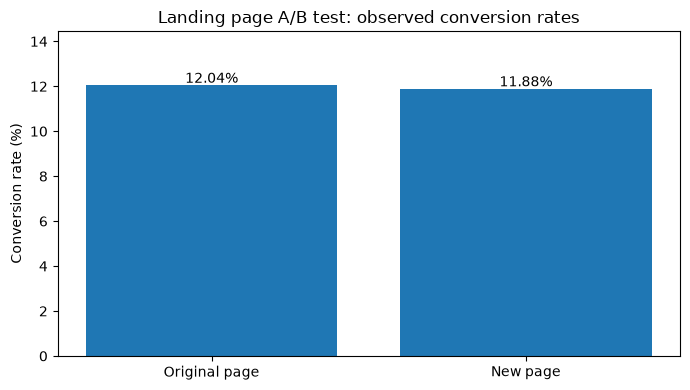

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Original page", "New page"], [control * 100, treatment * 100])
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Landing page A/B test: observed conversion rates")
ax.set_ylim(0, max(control, treatment) * 120)
for i, value in enumerate([control, treatment]):
    ax.text(i, value * 100 + .12, f"{value * 100:.2f}%", ha="center")
plt.tight_layout()
plt.show()

## 4. Hypothesis test and interval
- **H₀:** Control and treatment conversion probabilities are equal.
- **H₁:** They differ (two-sided).
- We use a two-proportion Z-test at significance level 0.05, plus a 95% confidence interval for (treatment − control).
- Statistical significance is **not** the same as business importance. The experiment's assignment mechanism and independence assumptions cannot be established from the CSV alone.

In [22]:
successes = [int(summary.loc["treatment", "conversions"]), int(summary.loc["control", "conversions"])]
sizes = [int(summary.loc["treatment", "users"]), int(summary.loc["control", "users"])]
z_stat, p_value = proportions_ztest(successes, sizes, alternative="two-sided")
ci_low, ci_high = confint_proportions_2indep(
    successes[0], sizes[0], successes[1], sizes[1],
    compare="diff", method="newcomb", alpha=0.05
)
print(f"Z statistic: {z_stat:.3f}")
print(f"Two-sided p-value: {p_value:.4f}")
print(f"95% CI for treatment - control: [{ci_low*100:.3f}, {ci_high*100:.3f}] percentage points")
print("Reject H0 at alpha=0.05?", p_value < 0.05)

Z statistic: -1.311
Two-sided p-value: 0.1899
95% CI for treatment - control: [-0.394, 0.078] percentage points
Reject H0 at alpha=0.05? False


## 5. Interpret the result
After running the notebook, write your findings **using the actual outputs**:

1. Control conversion rate: 12.0418%
2. Treatment conversion rate: 11.8831%
3. Absolute difference: (Treatment − Control): −0.1587 percentage points
4. P-value: 0.187589
5. 95% CI: [−0.3947, +0.0773] percentage points
6. Is there strong evidence of a difference? 
No. Since the p-value (0.187589) is greater than the significance level (0.05), we fail to reject the null hypothesis. There is insufficient statistical evidence of a difference in conversion rates.

7. Is the change large enough to matter to the business? What additional information would you need?
The observed difference is small, and its statistical uncertainty includes zero. The company would need information about revenue per conversion, implementation costs, and the minimum improvement considered worthwhile to determine its business importance.


Business Conclusion

The purpose of this analysis was to determine whether a redesigned landing page improved user conversion rates compared with the original website.

The primary analysis included 290,584 unique users, analyzed according to their assigned experiment groups.

The control group achieved a conversion rate of approximately 12.0418%, while the treatment group achieved approximately 11.8831%, resulting in an observed difference of −0.1587 percentage points.

A two-sided two-proportion Z-test produced a Z-statistic of −1.3177 and a p-value of 0.187589. Since the p-value exceeded the 0.05 significance threshold, we failed to reject the null hypothesis.

The 95% confidence interval for the conversion-rate difference was [−0.3947, +0.0773] percentage points, which includes zero.

Recommendation: The experiment does not provide sufficient statistical evidence that the redesigned landing page improves conversions. Therefore, the company should not implement the redesign solely to increase conversion rates based on these findings.

Additional experiments or an assessment of other business metrics may help determine whether the redesigned page offers meaningful benefits.

Limitations: The primary analysis retained each user's earliest recorded observation and assumes that this observation appropriately represents their experiment outcome. The dataset contains mismatches between assigned groups and displayed landing pages, and the experimental design has not been fully verified.

## 6. Next steps
- Analyze group sizes (sample-ratio mismatch check).
- Explore day-to-day conversion rates with the `timestamp` column.
- Establish a minimum detectable effect before future experiments.
- Write a short decision memo in README.md and include the figure.